# Evaluacion de modelos con datos desbalanceados

**Examen del Modulo 3 - Deteccion de fallas industriales**  
**Estudiante:** Raul Perez

## 1. Librerias y versiones

In [1]:
import importlib.metadata as metadata

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.datasets import make_classification
from sklearn.metrics import (
    accuracy_score,
    brier_score_loss,
    cohen_kappa_score,
    matthews_corrcoef,
)
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from imblearn.over_sampling import RandomOverSampler, SMOTE
from imblearn.pipeline import Pipeline
from imblearn.under_sampling import RandomUnderSampler

versiones = pd.Series({
    "Python": __import__("sys").version.split()[0],
    "NumPy": np.__version__,
    "pandas": pd.__version__,
    "Matplotlib": metadata.version("matplotlib"),
    "scikit-learn": sklearn.__version__,
    "imbalanced-learn": metadata.version("imbalanced-learn"),
}, name="Version")
display(versiones.to_frame())

,Version
Python,3.13.0
NumPy,2.3.2
pandas,3.0.5
Matplotlib,3.10.5
scikit-learn,1.9.1
imbalanced-learn,0.14.2


## 2. Generacion y particion estratificada de los datos

El dataset es sintético y simula lecturas de sensores de componentes industriales, con el objetivo de predecir si
un componente fallará en las próximas 24 horas. La clase positiva (falla) es poco frecuente (~3% de las
observaciones), por lo que el problema debe tratarse como clasificación binaria desbalanceada.

In [2]:
X, y = make_classification(
    n_samples=6000, n_features=12, n_informative=6, n_redundant=2,
    n_repeated=0, n_clusters_per_class=2, weights=[0.97, 0.03],
    flip_y=0.01, class_sep=0.9, random_state=42)

columnas = [f"sensor_{i}" for i in range(1, 13)]
df = pd.DataFrame(X, columns=columnas)
df["falla"] = y

La partición entrenamiento/prueba (80%/20%, estratificada) usa el mismo random_state=42.

In [3]:
X = df.drop(columns="falla")
y = df["falla"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42
)

print(f"Entrenamiento: {X_train.shape[0]:,} filas")
print(f"Prueba:        {X_test.shape[0]:,} filas")
print(f"Sensores:      {X_train.shape[1]}")

Entrenamiento: 4,800 filas
Prueba:        1,200 filas
Sensores:      12


### Distribucion de la variable objetivo

Se comprueba el conteo y el porcentaje de cada clase en el conjunto completo y en cada particion.

In [4]:
def resumen_clases(etiquetas, conjunto):
    conteos = etiquetas.value_counts().sort_index()
    return pd.DataFrame({
        "Conjunto": conjunto,
        "Clase": conteos.index,
        "Observaciones": conteos.values,
        "Porcentaje": (conteos.values / len(etiquetas) * 100).round(2),
    })

balance = pd.concat([
    resumen_clases(y, "Completo"),
    resumen_clases(y_train, "Entrenamiento"),
    resumen_clases(y_test, "Prueba"),
], ignore_index=True)
display(balance)

,Conjunto,Clase,Observaciones,Porcentaje
0,Completo,0,5799,96.65
1,Completo,1,201,3.35
2,Entrenamiento,0,4639,96.65
3,Entrenamiento,1,161,3.35
4,Prueba,0,1160,96.67
5,Prueba,1,40,3.33


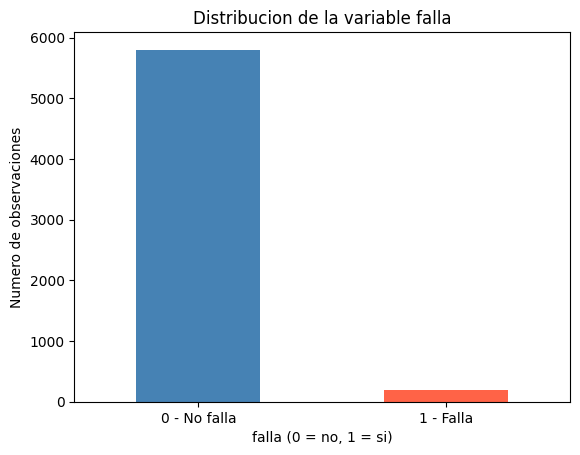

In [5]:
ax = y.value_counts().sort_index().plot.bar(color=["steelblue", "tomato"])
ax.set(title="Distribucion de la variable falla", xlabel="falla (0 = no, 1 = si)", ylabel="Numero de observaciones")
ax.set_xticklabels(["0 - No falla", "1 - Falla"], rotation=0)
plt.show()

Puede notarse que aproximadamente el 3% de los registros corresponden a un fallo. Coherente con el establecimiento de la simulación de los datos. Esta situación es típica de datos desbalanceados por lo que es necesario su correspondiente tratamiento.

## 3. Configuracion de modelos y validacion cruzada

Se usa la misma Regresion Logistica en las cinco configuraciones (`max_iter=1000`, `random_state=42`). La unica excepcion es el parametro adicional `class_weight="balanced"`. En las estrategias de remuestreo, el sampler forma parte del pipeline y se aplica unicamente a los datos de entrenamiento de cada fold. Se evalua MCC mediante validacion cruzada estratificada de cinco folds.

In [6]:
modelo_base = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', LogisticRegression(max_iter=1000, random_state=42))
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
puntajes_base = cross_val_score(modelo_base, X_train, y_train, cv=cv, scoring="matthews_corrcoef", n_jobs=1)
resultados_base = {'modelo': 'Base', 'MCC medio': puntajes_base.mean(), 'Desviación estándar': puntajes_base.std(ddof=1)}

print(f'MCC medio: {resultados_base["MCC medio"]:.4f}')
print(f'Desviación estándar: {resultados_base["Desviación estándar"]:.4f}')


MCC medio: 0.1402
Desviación estándar: 0.0848


In [7]:
modelo_sobremuestreo = Pipeline([
    ('scaler', StandardScaler()),
    ('oversampler', RandomOverSampler(random_state=42)),
    ('classifier', LogisticRegression(max_iter=1000, random_state=42))
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
puntajes_sobremuestreo = cross_val_score(modelo_sobremuestreo, X_train, y_train, cv=cv, scoring="matthews_corrcoef", n_jobs=1)

resultados_sobremuestreo = {'modelo': 'Sobremuestreo', 'MCC medio': puntajes_sobremuestreo.mean(), 'Desviación estándar': puntajes_sobremuestreo.std(ddof=1)}

print(f'MCC medio: {resultados_sobremuestreo["MCC medio"]:.4f}')
print(f'Desviación estándar: {resultados_sobremuestreo["Desviación estándar"]:.4f}')


MCC medio: 0.2240
Desviación estándar: 0.0324


In [8]:
modelo_submuestreo = Pipeline([
    ('scaler', StandardScaler()),
    ('undersampler', RandomUnderSampler(random_state=42)),
    ('classifier', LogisticRegression(max_iter=1000, random_state=42))
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
puntajes_submuestreo = cross_val_score(modelo_submuestreo, X_train, y_train, cv=cv, scoring="matthews_corrcoef", n_jobs=1)
resultados_submuestreo = {'modelo': 'Submuestreo', 'MCC medio': puntajes_submuestreo.mean(), 'Desviación estándar': puntajes_submuestreo.std(ddof=1)}

print(f'MCC medio: {resultados_submuestreo["MCC medio"]:.4f}')
print(f'Desviación estándar: {resultados_submuestreo["Desviación estándar"]:.4f}')


MCC medio: 0.2273
Desviación estándar: 0.0323


In [9]:
modelo_smote = Pipeline([
    ('scaler', StandardScaler()),
    ('SMOTE', SMOTE(random_state=42)),
    ('classifier', LogisticRegression(max_iter=1000, random_state=42))
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
puntajes_smote = cross_val_score(modelo_smote, X_train, y_train, cv=cv, scoring="matthews_corrcoef", n_jobs=1)
resultados_smote = {'modelo': 'SMOTE', 'MCC medio': puntajes_smote.mean(), 'Desviación estándar': puntajes_smote.std(ddof=1)}

print(f'MCC medio: {resultados_smote["MCC medio"]:.4f}')
print(f'Desviación estándar: {resultados_smote["Desviación estándar"]:.4f}')


MCC medio: 0.2231
Desviación estándar: 0.0319


In [10]:
modelo_balanced = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', LogisticRegression(max_iter=1000, random_state=42,class_weight='balanced'))
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
puntajes_balanced = cross_val_score(modelo_balanced, X_train, y_train, cv=cv, scoring="matthews_corrcoef", n_jobs=1)
resultados_balanced = {'modelo': 'Balanced', 'MCC medio': puntajes_balanced.mean(), 'Desviación estándar': puntajes_balanced.std(ddof=1)}

print(f'MCC medio: {resultados_balanced["MCC medio"]:.4f}')
print(f'Desviación estándar: {resultados_balanced["Desviación estándar"]:.4f}')


MCC medio: 0.2283
Desviación estándar: 0.0329


In [11]:
resultados = pd.DataFrame([
    resultados_base,
    resultados_sobremuestreo,
    resultados_submuestreo,
    resultados_smote,
    resultados_balanced
])
resultados = resultados.sort_values(by="MCC medio", ascending=False).reset_index(drop=True)
resultados

,modelo,MCC medio,Desviación estándar
0,Balanced,0.228322,0.032913
1,Submuestreo,0.227267,0.032312
2,Sobremuestreo,0.224033,0.032370
3,SMOTE,0.223090,0.031947
4,Base,0.140198,0.084816


## 4. Evaluacion final en el conjunto de prueba

Una vez terminada la validacion cruzada, cada configuracion se ajusta sobre todo el conjunto de entrenamiento y se evalua una sola vez en la prueba. Se mantiene el umbral de clasificacion predeterminado de 0.5.

In [12]:
modelos = {
    "Base": modelo_base,
    "Sobremuestreo": modelo_sobremuestreo,
    "Submuestreo": modelo_submuestreo,
    "SMOTE": modelo_smote,
    "Balanced": modelo_balanced,
}

resultados_prueba = []
modelos_ajustados = {}

for nombre, modelo in modelos.items():
    modelo.fit(X_train, y_train)
    modelos_ajustados[nombre] = modelo
    predicciones = modelo.predict(X_test)
    resultados_prueba.append({
        "Configuracion": nombre,
        "Exactitud": accuracy_score(y_test, predicciones),
        "MCC": matthews_corrcoef(y_test, predicciones),
        "Kappa de Cohen": cohen_kappa_score(y_test, predicciones),
    })

In [13]:
resultados_prueba = pd.DataFrame(resultados_prueba)
resultados_prueba = resultados_prueba.sort_values(by="MCC", ascending=False).reset_index(drop=True)
resultados_prueba

,Configuracion,Exactitud,MCC,Kappa de Cohen
0,SMOTE,0.800000,0.259998,0.162011
1,Sobremuestreo,0.785000,0.257039,0.154283
2,Balanced,0.784167,0.246781,0.148400
3,Submuestreo,0.770000,0.245328,0.142502
4,Base,0.965833,0.168659,0.118911


Como solo alrededor del 3.35% de los casos son fallas, predecir siempre "no falla" ya produciria una exactitud cercana al 96.65% (Como parece suceder con la configuracion Base), aunque no detectaria ninguna falla; por eso la exactitud es poco informativa por si sola.
Para ello mediante el MCC y Kappa de Cohen proporcionan informacion para saber si en realidad no depende un modelo del azar y con los valores mas pequeños de ambos ahora el modelo Base queda como el peor.

Se recomienda la configuracion con mayor MCC medio en la validacion cruzada del conjunto de entrenamiento; el conjunto de prueba no se usa para seleccionarla. En ese caso, la ponderacion balanceada es una alternativa practica porque evita duplicar la clase minoritaria o descartar observaciones de la clase mayoritaria, por ello se recomienda el modelo Balanced.

## 5. Calibracion de probabilidades

Se calibra la estrategia recomendada con `CalibratedClassifierCV(method="sigmoid")`. La calibracion se ajusta unicamente con datos de entrenamiento mediante folds estratificados. Se comparan las probabilidades del modelo ajustado sin calibrar y calibrado en las mismas observaciones de prueba. Se usa una curva de confiabilidad con diez bins de igual frecuencia y el Brier score (menor es mejor).

In [14]:
mejor_modelo = modelo_balanced
probabilidades_antes = mejor_modelo.predict_proba(X_test)[:, 1]

cv_calibracion = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
modelo_calibrado = CalibratedClassifierCV(
    estimator=mejor_modelo,
    method="sigmoid",
    cv=cv_calibracion,
)

modelo_calibrado.fit(X_train, y_train)
probabilidades_despues = modelo_calibrado.predict_proba(X_test)[:, 1]

brier_antes = brier_score_loss(y_test, probabilidades_antes)
brier_despues = brier_score_loss(y_test, probabilidades_despues)
print(f"Estrategia calibrada: {mejor_modelo}")
print(f"Brier score antes:   {brier_antes:.4f}")
print(f"Brier score despues: {brier_despues:.4f}")

Estrategia calibrada: Pipeline(steps=[('scaler', StandardScaler()),
                ('classifier',
                 LogisticRegression(class_weight='balanced', max_iter=1000,
                                    random_state=42))])
Brier score antes:   0.1549
Brier score despues: 0.0287


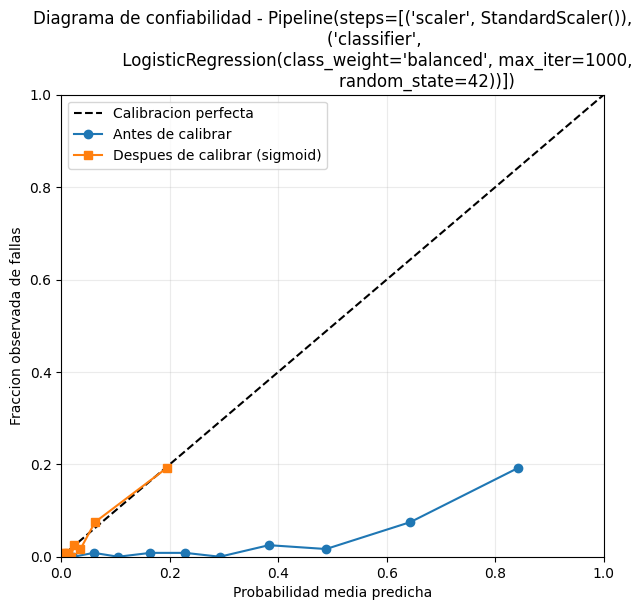

In [15]:
fraccion_positivos_antes, media_predicha_antes = calibration_curve(
    y_test, probabilidades_antes, n_bins=10, strategy="quantile"
)
fraccion_positivos_despues, media_predicha_despues = calibration_curve(
    y_test, probabilidades_despues, n_bins=10, strategy="quantile"
)

fig, ax = plt.subplots(figsize=(7, 6))
ax.plot([0, 1], [0, 1], "k--", label="Calibracion perfecta")
ax.plot(media_predicha_antes, fraccion_positivos_antes, "o-", label="Antes de calibrar")
ax.plot(media_predicha_despues, fraccion_positivos_despues, "s-", label="Despues de calibrar (sigmoid)")
ax.set(
    title=f"Diagrama de confiabilidad - {mejor_modelo}",
    xlabel="Probabilidad media predicha",
    ylabel="Fraccion observada de fallas",
    xlim=(0, 1),
    ylim=(0, 1),
)
ax.legend()
ax.grid(alpha=0.25)
plt.show()

El brier score del modelo calibrado es menor vs el brier score del modelo sin calibrar, además, el diagrama de confiabilidad muestra que la probabilidad media predicha del modelo calibrado son puntos que quedan cerca de la diagonal ideal, algo completamente diferente al comportamiento del modelo sin calibrar.